In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import time

from io import StringIO
from requests.exceptions import ReadTimeout, ConnectionError

base_url = "https://data.cityofchicago.org/resource/68nd-jvt3.csv"

where_clause = (
    "crash_date >= '2024-01-01T00:00:00' "
    "AND crash_date < '2026-01-01T00:00:00'"
)

columns = [
    "crash_unit_id",
    "crash_record_id",
    "crash_date",
    "unit_no",
    "unit_type",
    "num_passengers",
    "vehicle_id",
    "make",
    "model",
    "vehicle_year",
    "vehicle_defect",
    "vehicle_type",
    "vehicle_use",
    "travel_direction",
    "maneuver",
    "occupant_cnt"
]

select_clause = ",".join(columns)


limit = 10000
offset = 0

all_parts = []


while True:

    params = {
        "$select": select_clause,
        "$where": where_clause,
        "$limit": limit,
        "$offset": offset,
        "$order": "crash_date ASC, crash_record_id ASC, crash_unit_id ASC"
    }

    print(f"Downloading Vehicles: offset {offset}...")

    max_retries = 5

    for attempt in range(max_retries):

        try:
            r = requests.get(
                base_url,
                params=params,
                timeout=180
            )

            r.raise_for_status()

            break

        except (ReadTimeout, ConnectionError) as e:

            print(f"Request failed: {e}")
            print(f"Retry {attempt + 1}/{max_retries}")

            time.sleep(5)

    else:
        raise Exception("Vehicles API failed after multiple retries.")

    part = pd.read_csv(StringIO(r.text))

    print(f"Downloaded {len(part)} rows")

    if len(part) == 0:
        break

    all_parts.append(part)

    if len(part) < limit:
        break

    offset += limit

vehicles = pd.concat(
    all_parts,
    ignore_index=True
)


vehicles["crash_date"] = pd.to_datetime(
    vehicles["crash_date"],
    errors="coerce"
)


print("\nVehicles dataset shape:")
print(vehicles.shape)

print("\nDate range:")
print(vehicles["crash_date"].min())
print(vehicles["crash_date"].max())

print("\nRows by year:")
print(
    vehicles["crash_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nColumns:")
print(vehicles.columns.tolist())


vehicles.to_csv(
    "chicago_vehicles_2024_2025.csv",
    index=False
)

print("\nSaved: chicago_vehicles_2024_2025.csv")

Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded

In [2]:
base_url = "https://data.cityofchicago.org/resource/u6pd-qa9d.csv"

where_clause = (
    "crash_date >= '2024-01-01T00:00:00' "
    "AND crash_date < '2026-01-01T00:00:00'"
)

columns = [
    "person_id",
    "person_type",
    "crash_record_id",
    "vehicle_id",
    "crash_date",
    "sex",
    "age",
    "drivers_license_state",
    "drivers_license_class",
    "safety_equipment",
    "airbag_deployed",
    "ejection",
    "injury_classification",
    "hospital",
    "driver_action",
    "driver_vision",
    "physical_condition"
]

select_clause = ",".join(columns)


limit = 10000
offset = 0

all_parts = []


while True:

    params = {
        "$select": select_clause,
        "$where": where_clause,
        "$limit": limit,
        "$offset": offset,
        "$order": "crash_date ASC, crash_record_id ASC, person_id ASC"
    }

    print(f"Downloading People: offset {offset}...")

    max_retries = 5

    for attempt in range(max_retries):

        try:
            r = requests.get(
                base_url,
                params=params,
                timeout=180
            )

            r.raise_for_status()

            break

        except (ReadTimeout, ConnectionError) as e:

            print(f"Request failed: {e}")
            print(f"Retry {attempt + 1}/{max_retries}")

            time.sleep(5)

    else:
        raise Exception("People API failed after multiple retries.")

    part = pd.read_csv(StringIO(r.text))

    print(f"Downloaded {len(part)} rows")

    if len(part) == 0:
        break

    all_parts.append(part)

    if len(part) < limit:
        break

    offset += limit



people = pd.concat(
    all_parts,
    ignore_index=True
)



people["crash_date"] = pd.to_datetime(
    people["crash_date"],
    errors="coerce"
)



print("\nPeople dataset shape:")
print(people.shape)

print("\nDate range:")
print(people["crash_date"].min())
print(people["crash_date"].max())

print("\nRows by year:")
print(
    people["crash_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("\nColumns:")
print(people.columns.tolist())


people.to_csv(
    "chicago_people_2024_2025.csv",
    index=False
)

print("\nSaved: chicago_people_2024_2025.csv")

Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded 10000 rows
Downloaded

In [3]:
base_url = "https://data.cityofchicago.org/resource/85ca-t3if.csv"



columns = [
    "crash_record_id",
    "crash_date",
    "posted_speed_limit",
    "traffic_control_device",
    "device_condition",
    "weather_condition",
    "lighting_condition",
    "first_crash_type",
    "trafficway_type",
    "alignment",
    "roadway_surface_cond",
    "road_defect",
    "prim_contributory_cause",
    "num_units",
    "most_severe_injury",
    "injuries_total",
    "injuries_fatal",
    "injuries_incapacitating",
    "latitude",
    "longitude"
]

select_clause = ",".join(columns)



def download_crashes_year(year):

    start_date = f"{year}-01-01T00:00:00"
    end_date = f"{year + 1}-01-01T00:00:00"

    where_clause = (
        f"crash_date >= '{start_date}' "
        f"AND crash_date < '{end_date}'"
    )

    limit = 10000
    offset = 0

    parts = []

    while True:

        params = {
            "$select": select_clause,
            "$where": where_clause,

            # IMPORTANT:
            # stable sorting using two fields
            "$order": "crash_date ASC, crash_record_id ASC",

            "$limit": limit,
            "$offset": offset
        }

        print(
            f"Year {year}: downloading offset {offset}..."
        )

        max_retries = 5

        for attempt in range(max_retries):

            try:

                r = requests.get(
                    base_url,
                    params=params,
                    timeout=180
                )

                r.raise_for_status()

                break

            except (ReadTimeout, ConnectionError) as e:

                print(
                    f"Request failed. "
                    f"Retry {attempt + 1}/{max_retries}"
                )

                time.sleep(5)

        else:
            raise Exception(
                f"Failed to download year {year}"
            )

        part = pd.read_csv(
            StringIO(r.text)
        )

        print(
            f"Downloaded {len(part)} rows"
        )

        if len(part) == 0:
            break

        parts.append(part)

        if len(part) < limit:
            break

        offset += limit


    year_df = pd.concat(
        parts,
        ignore_index=True
    )

    return year_df

In [4]:
crashes_2024 = download_crashes_year(2024)

Year 2024: downloading offset 0...
Downloaded 10000 rows
Year 2024: downloading offset 10000...
Downloaded 10000 rows
Year 2024: downloading offset 20000...
Downloaded 10000 rows
Year 2024: downloading offset 30000...
Downloaded 10000 rows
Year 2024: downloading offset 40000...
Downloaded 10000 rows
Year 2024: downloading offset 50000...
Downloaded 10000 rows
Year 2024: downloading offset 60000...
Downloaded 10000 rows
Year 2024: downloading offset 70000...
Downloaded 10000 rows
Year 2024: downloading offset 80000...
Downloaded 10000 rows
Year 2024: downloading offset 90000...
Downloaded 10000 rows
Year 2024: downloading offset 100000...
Downloaded 10000 rows
Year 2024: downloading offset 110000...
Downloaded 2057 rows


In [5]:
print(crashes_2024.shape)

print(
    "Unique crash IDs:",
    crashes_2024["crash_record_id"].nunique()
)

print(
    "Duplicate crash IDs:",
    crashes_2024["crash_record_id"]
    .duplicated()
    .sum()
)

(112057, 20)
Unique crash IDs: 112057
Duplicate crash IDs: 0


In [6]:
crashes_2025 = download_crashes_year(2025)

Year 2025: downloading offset 0...
Downloaded 10000 rows
Year 2025: downloading offset 10000...
Downloaded 10000 rows
Year 2025: downloading offset 20000...
Downloaded 10000 rows
Year 2025: downloading offset 30000...
Downloaded 10000 rows
Year 2025: downloading offset 40000...
Downloaded 10000 rows
Year 2025: downloading offset 50000...
Downloaded 10000 rows
Year 2025: downloading offset 60000...
Downloaded 10000 rows
Year 2025: downloading offset 70000...
Downloaded 10000 rows
Year 2025: downloading offset 80000...
Downloaded 10000 rows
Year 2025: downloading offset 90000...
Downloaded 10000 rows
Year 2025: downloading offset 100000...
Downloaded 9118 rows


In [7]:
print(crashes_2025.shape)

print(
    "Unique crash IDs:",
    crashes_2025["crash_record_id"].nunique()
)

print(
    "Duplicate crash IDs:",
    crashes_2025["crash_record_id"]
    .duplicated()
    .sum()
)

(109118, 20)
Unique crash IDs: 109118
Duplicate crash IDs: 0


In [8]:
# Combine the two yearly crash datasets
crashes_fixed = pd.concat(
    [crashes_2024, crashes_2025],
    ignore_index=True
)

# Convert crash_date to datetime
crashes_fixed["crash_date"] = pd.to_datetime(
    crashes_fixed["crash_date"],
    errors="coerce"
)

print(
    crashes_fixed["crash_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

crash_date
2024    112057
2025    109118
Name: count, dtype: int64


In [9]:
crash_ids = set(
    crashes_fixed["crash_record_id"].dropna()
)

vehicle_ids = set(
    vehicles["crash_record_id"].dropna()
)

people_ids = set(
    people["crash_record_id"].dropna()
)

print(
    "Vehicle coverage:",
    len(crash_ids & vehicle_ids) / len(crash_ids)
)

print(
    "People coverage:",
    len(crash_ids & people_ids) / len(crash_ids)
)

print(
    "Vehicle IDs not in crashes:",
    len(vehicle_ids - crash_ids)
)

print(
    "People IDs not in crashes:",
    len(people_ids - crash_ids)
)

Vehicle coverage: 1.0
People coverage: 0.9979021137108625
Vehicle IDs not in crashes: 0
People IDs not in crashes: 0


In [10]:
crashes = crashes_fixed.copy()

print("Crashes:", crashes.shape)
print("Vehicles:", vehicles.shape)
print("People:", people.shape)

Crashes: (221175, 20)
Vehicles: (450185, 16)
People: (485110, 17)


In [11]:
vehicles_clean = vehicles[
    vehicles["crash_record_id"].isin(
        crashes["crash_record_id"]
    )
].copy()

print("Original vehicles:", vehicles.shape)
print("Matched vehicles:", vehicles_clean.shape)

Original vehicles: (450185, 16)
Matched vehicles: (450185, 16)


In [12]:
people_clean = people[
    people["crash_record_id"].isin(
        crashes["crash_record_id"]
    )
].copy()

print("Original people:", people.shape)
print("Matched people:", people_clean.shape)

Original people: (485110, 17)
Matched people: (485110, 17)


In [13]:
print(
    "Crash duplicates:",
    crashes["crash_record_id"]
    .duplicated()
    .sum()
)

print(
    "Vehicle IDs outside crashes:",
    (~vehicles_clean["crash_record_id"]
     .isin(crashes["crash_record_id"]))
    .sum()
)

print(
    "People IDs outside crashes:",
    (~people_clean["crash_record_id"]
     .isin(crashes["crash_record_id"]))
    .sum()
)

Crash duplicates: 0
Vehicle IDs outside crashes: 0
People IDs outside crashes: 0


In [14]:
crashes.to_csv(
    "chicago_crashes_2024_2025_clean_base.csv",
    index=False
)

vehicles_clean.to_csv(
    "chicago_vehicles_2024_2025_clean_base.csv",
    index=False
)

people_clean.to_csv(
    "chicago_people_2024_2025_clean_base.csv",
    index=False
)

In [15]:
crashes["crash_date"] = pd.to_datetime(
    crashes["crash_date"],
    errors="coerce"
)

In [16]:
print(crashes["crash_date"].min())
print(crashes["crash_date"].max())

print(
    crashes["crash_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

2024-01-01 00:00:00
2025-12-31 23:52:00
crash_date
2024    112057
2025    109118
Name: count, dtype: int64


In [17]:
crashes["year"] = crashes["crash_date"].dt.year
crashes["month"] = crashes["crash_date"].dt.month
crashes["hour"] = crashes["crash_date"].dt.hour
crashes["day_of_week"] = crashes["crash_date"].dt.day_name()

In [18]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

crashes["day_of_week"] = pd.Categorical(
    crashes["day_of_week"],
    categories=weekday_order,
    ordered=True
)

In [19]:
fatal_check = crashes[
    crashes["injuries_fatal"].fillna(0) > 0
][
    [
        "most_severe_injury",
        "injuries_total",
        "injuries_fatal",
        "injuries_incapacitating"
    ]
]

print(fatal_check.head(20))

print(
    fatal_check["most_severe_injury"]
    .value_counts(dropna=False)
)

      most_severe_injury  injuries_total  injuries_fatal  \
4286               FATAL             2.0             1.0   
5279               FATAL             1.0             1.0   
5327               FATAL             1.0             1.0   
7697               FATAL             1.0             1.0   
8711               FATAL             1.0             1.0   
10117              FATAL             1.0             1.0   
10303              FATAL             1.0             1.0   
10938              FATAL             8.0             1.0   
13947              FATAL             1.0             1.0   
14665              FATAL             2.0             1.0   
14695              FATAL             2.0             2.0   
16177              FATAL             1.0             1.0   
16665              FATAL             1.0             1.0   
17665              FATAL             2.0             1.0   
19440              FATAL             1.0             1.0   
19461              FATAL             2.0

In [20]:
severity_map = {
    "FATAL": "Fatal",
    "INCAPACITATING INJURY": "Serious Injury",
    "NONINCAPACITATING INJURY": "Minor Injury",
    "REPORTED, NOT EVIDENT": "Minor Injury",
    "NO INDICATION OF INJURY": "No Injury"
}

crashes["severity_group"] = (
    crashes["most_severe_injury"]
    .map(severity_map)
)

In [21]:
# import numpy as np
crashes["severe_crash"] = np.where(
    crashes["severity_group"].isna(),
    np.nan,
    np.where(
        crashes["severity_group"].isin(
            ["Fatal", "Serious Injury"]
        ),
        1,
        0
    )
)

In [22]:
print(
    crashes["severity_group"]
    .value_counts(dropna=False)
)

severity_group
No Injury         184364
Minor Injury       33033
Serious Injury      3116
NaN                  466
Fatal                196
Name: count, dtype: int64


In [23]:
print(
    crashes["severe_crash"]
    .value_counts(dropna=False)
)

print(
    crashes["severe_crash"]
    .value_counts(normalize=True, dropna=False)
)

severe_crash
0.0    217397
1.0      3312
NaN       466
Name: count, dtype: int64
severe_crash
0.0    0.982919
1.0    0.014975
NaN    0.002107
Name: proportion, dtype: float64


In [24]:
crashes["severe_crash"].mean()

0.015006184614129918

In [25]:
weather_map = {
    "CLEAR": "Clear",
    "CLOUDY/OVERCAST": "Cloudy",
    "RAIN": "Rain",
    "SNOW": "Snow",

    "FREEZING RAIN/DRIZZLE": "Wintry Mix",
    "SLEET/HAIL": "Wintry Mix",
    "BLOWING SNOW": "Wintry Mix",

    "FOG/SMOKE/HAZE": "Reduced Visibility",
    "BLOWING SAND, SOIL, DIRT": "Reduced Visibility",

    "SEVERE CROSS WIND GATE": "Other",
    "OTHER": "Other",

    "UNKNOWN": "Unknown"
}

crashes["weather_group"] = (
    crashes["weather_condition"]
    .map(weather_map)
)

In [26]:
lighting_map = {
    "DAYLIGHT": "Daylight",
    "DARKNESS, LIGHTED ROAD": "Dark - Lighted Road",
    "DARKNESS": "Dark - Unlighted",
    "DUSK": "Dusk",
    "DAWN": "Dawn",
    "UNKNOWN": "Unknown"
}

crashes["lighting_group"] = (
    crashes["lighting_condition"]
    .map(lighting_map)
)

In [27]:
road_surface_map = {
    "DRY": "Dry",
    "WET": "Wet",
    "SNOW OR SLUSH": "Snow/Slush",
    "ICE": "Ice",
    "SAND, MUD, DIRT": "Other",
    "OTHER": "Other",
    "UNKNOWN": "Unknown"
}

crashes["road_surface_group"] = (
    crashes["roadway_surface_cond"]
    .map(road_surface_map)
)

print(
    crashes["road_surface_group"]
    .value_counts(dropna=False)
)

road_surface_group
Dry           159507
Unknown        30080
Wet            23704
Snow/Slush      5509
Ice             1631
Other            744
Name: count, dtype: int64


In [28]:
def speed_group(x):

    if pd.isna(x):
        return np.nan

    if x == 0:
        return "0 / Unknown"

    elif x <= 20:
        return "1–20 mph"

    elif x <= 25:
        return "21–25 mph"

    elif x <= 30:
        return "26–30 mph"

    elif x <= 35:
        return "31–35 mph"

    elif x <= 40:
        return "36–40 mph"

    else:
        return "41+ mph"


crashes["speed_limit_group"] = (
    crashes["posted_speed_limit"]
    .apply(speed_group)
)

In [29]:
speed_order = [
    "0 / Unknown",
    "1–20 mph",
    "21–25 mph",
    "26–30 mph",
    "31–35 mph",
    "36–40 mph",
    "41+ mph"
]

crashes["speed_limit_group"] = pd.Categorical(
    crashes["speed_limit_group"],
    categories=speed_order,
    ordered=True
)

In [30]:
weather_analysis = crashes[
    (crashes["weather_group"] != "Unknown")
    & (crashes["weather_group"].notna())
    & (crashes["severe_crash"].notna())
].copy()

print(
    weather_analysis["weather_group"]
    .value_counts()
)

weather_severity = (
    weather_analysis
    .groupby(
        "weather_group",
        observed=True
    )
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

weather_severity["severe_crash_rate_pct"] = (
    weather_severity["severe_crash_rate"] * 100
)

weather_severity = (
    weather_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
)


print("\nWeather severity summary:")
print(weather_severity)

weather_group
Clear                 173103
Rain                   15763
Cloudy                  6206
Snow                    5658
Wintry Mix              1300
Other                    823
Reduced Visibility       232
Name: count, dtype: int64

Weather severity summary:
        weather_group  total_crashes  severe_crashes  severe_crash_rate  \
3                Rain          15763           311.0           0.019730   
0               Clear         173103          2771.0           0.016008   
2               Other            823            10.0           0.012151   
1              Cloudy           6206            71.0           0.011441   
5                Snow           5658            64.0           0.011311   
6          Wintry Mix           1300            13.0           0.010000   
4  Reduced Visibility            232             2.0           0.008621   

   severe_crash_rate_pct  
3               1.972975  
0               1.600781  
2               1.215067  
1               1.144

In [31]:
lighting_analysis = crashes[
    (crashes["lighting_group"] != "Unknown")
    & (crashes["lighting_group"].notna())
    & (crashes["severe_crash"].notna())
].copy()


road_analysis = crashes[
    (crashes["road_surface_group"] != "Unknown")
    & (crashes["road_surface_group"].notna())
    & (crashes["severe_crash"].notna())
].copy()


speed_analysis = crashes[
    (crashes["speed_limit_group"] != "0 / Unknown")
    & (crashes["speed_limit_group"].notna())
    & (crashes["severe_crash"].notna())
].copy()

In [32]:
lighting_severity = (
    lighting_analysis
    .groupby(
        "lighting_group",
        observed=True
    )
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

lighting_severity["severe_crash_rate_pct"] = (
    lighting_severity["severe_crash_rate"] * 100
)

lighting_severity = (
    lighting_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
)

print(lighting_severity)

        lighting_group  total_crashes  severe_crashes  severe_crash_rate  \
0  Dark - Lighted Road          46518          1103.0           0.023711   
2                 Dawn           3576            70.0           0.019575   
4                 Dusk           5797           106.0           0.018285   
1     Dark - Unlighted           9527           167.0           0.017529   
3             Daylight         141390          1814.0           0.012830   

   severe_crash_rate_pct  
0               2.371125  
2               1.957494  
4               1.828532  
1               1.752913  
3               1.282976  


In [33]:
road_severity = (
    road_analysis
    .groupby(
        "road_surface_group",
        observed=True
    )
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

road_severity["severe_crash_rate_pct"] = (
    road_severity["severe_crash_rate"] * 100
)

road_severity = (
    road_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
)

print(road_severity)

  road_surface_group  total_crashes  severe_crashes  severe_crash_rate  \
4                Wet          23638           436.0           0.018445   
0                Dry         159191          2621.0           0.016464   
2              Other            742            11.0           0.014825   
3         Snow/Slush           5488            58.0           0.010569   
1                Ice           1628            14.0           0.008600   

   severe_crash_rate_pct  
4               1.844488  
0               1.646450  
2               1.482480  
3               1.056851  
1               0.859951  


In [34]:
speed_severity = (
    speed_analysis
    .groupby(
        "speed_limit_group",
        observed=True
    )
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

speed_severity["severe_crash_rate_pct"] = (
    speed_severity["severe_crash_rate"] * 100
)

print(speed_severity)

  speed_limit_group  total_crashes  severe_crashes  severe_crash_rate  \
0          1–20 mph          23988           172.0           0.007170   
1         21–25 mph          16376           192.0           0.011724   
2         26–30 mph         164056          2564.0           0.015629   
3         31–35 mph          12031           267.0           0.022193   
4         36–40 mph           2230            83.0           0.037220   
5           41+ mph           1639            30.0           0.018304   

   severe_crash_rate_pct  
0               0.717025  
1               1.172447  
2               1.562881  
3               2.219267  
4               3.721973  
5               1.830384  


In [35]:
#dataset for combined weather and lighting analysis
environment_analysis = crashes[
    crashes["weather_group"].notna()
    & crashes["lighting_group"].notna()
    & (crashes["weather_group"] != "Unknown")
    & (crashes["lighting_group"] != "Unknown")
    & crashes["severe_crash"].notna()
].copy()

print("Records used:", len(environment_analysis))


environment_pivot = pd.pivot_table(
    environment_analysis,
    values="severe_crash",
    index="lighting_group",
    columns="weather_group",
    aggfunc="mean"
) * 100

print(
    environment_pivot
    .round(2)
)

Records used: 200323
weather_group        Clear  Cloudy  Other  Rain  Reduced Visibility  Snow  \
lighting_group                                                              
Dark - Lighted Road   2.43    2.14   2.53  2.94                1.49  1.68   
Dark - Unlighted      1.80    1.11   1.64  2.70                0.00  1.15   
Dawn                  1.89    0.91   0.00  2.77                8.33  3.08   
Daylight              1.34    0.99   1.05  1.30                0.00  0.80   
Dusk                  1.94    2.13   0.00  1.51                0.00  0.52   

weather_group        Wintry Mix  
lighting_group                   
Dark - Lighted Road        1.04  
Dark - Unlighted           0.00  
Dawn                       0.00  
Daylight                   1.05  
Dusk                       5.41  


In [36]:
severity_descriptive = (
    crashes[
        crashes["severe_crash"].notna()
    ]
    .groupby("severe_crash")
    .agg(
        crashes=("crash_record_id", "count"),
        mean_speed_limit=("posted_speed_limit", "mean"),
        median_speed_limit=("posted_speed_limit", "median"),
        mean_num_units=("num_units", "mean")
    )
    .round(2)
)

severity_descriptive = severity_descriptive.rename(
    index={
        0.0: "Non-Severe",
        1.0: "Severe"
    }
)

print(severity_descriptive)

              crashes  mean_speed_limit  median_speed_limit  mean_num_units
severe_crash                                                               
Non-Severe     217397             28.48                30.0            2.03
Severe           3312             29.74                30.0            2.13


In [37]:
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.titleweight": "semibold"
})

def style_axes(ax, grid_axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if grid_axis is not None:
        ax.grid(
            axis=grid_axis,
            linestyle="--",
            linewidth=0.7,
            alpha=0.3
        )

    ax.set_axisbelow(True)

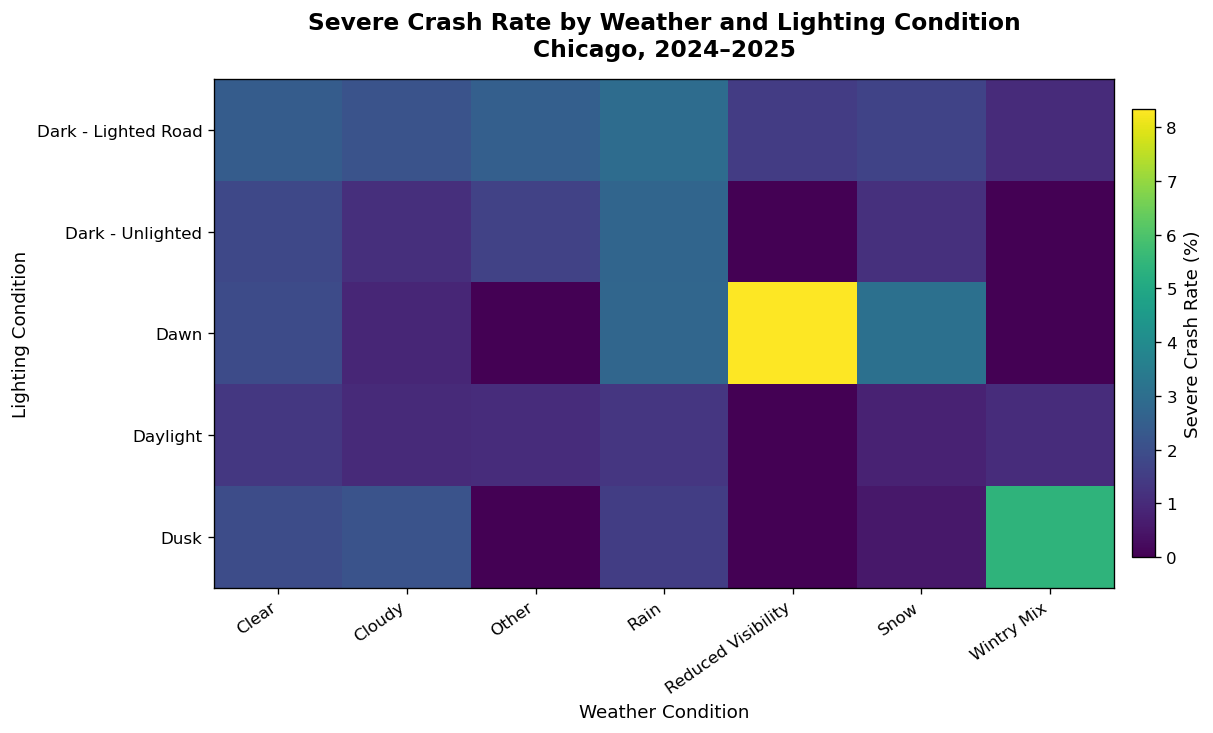

In [38]:
fig, ax = plt.subplots(
    figsize=(10, 6),
    constrained_layout=True
)

im = ax.imshow(
    environment_pivot,
    aspect="auto",
    interpolation="nearest"
)

cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.88,
    pad=0.02
)

cbar.set_label("Severe Crash Rate (%)")

ax.set_xticks(
    np.arange(len(environment_pivot.columns))
)
ax.set_xticklabels(
    environment_pivot.columns,
    rotation=35,
    ha="right"
)

ax.set_yticks(
    np.arange(len(environment_pivot.index))
)
ax.set_yticklabels(
    environment_pivot.index
)

ax.set_xlabel("Weather Condition")
ax.set_ylabel("Lighting Condition")

ax.set_title(
    "Severe Crash Rate by Weather and Lighting Condition\n"
    "Chicago, 2024–2025",
    pad=14
)

plt.savefig(
    "weather_lighting_severe_rate_heatmap.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

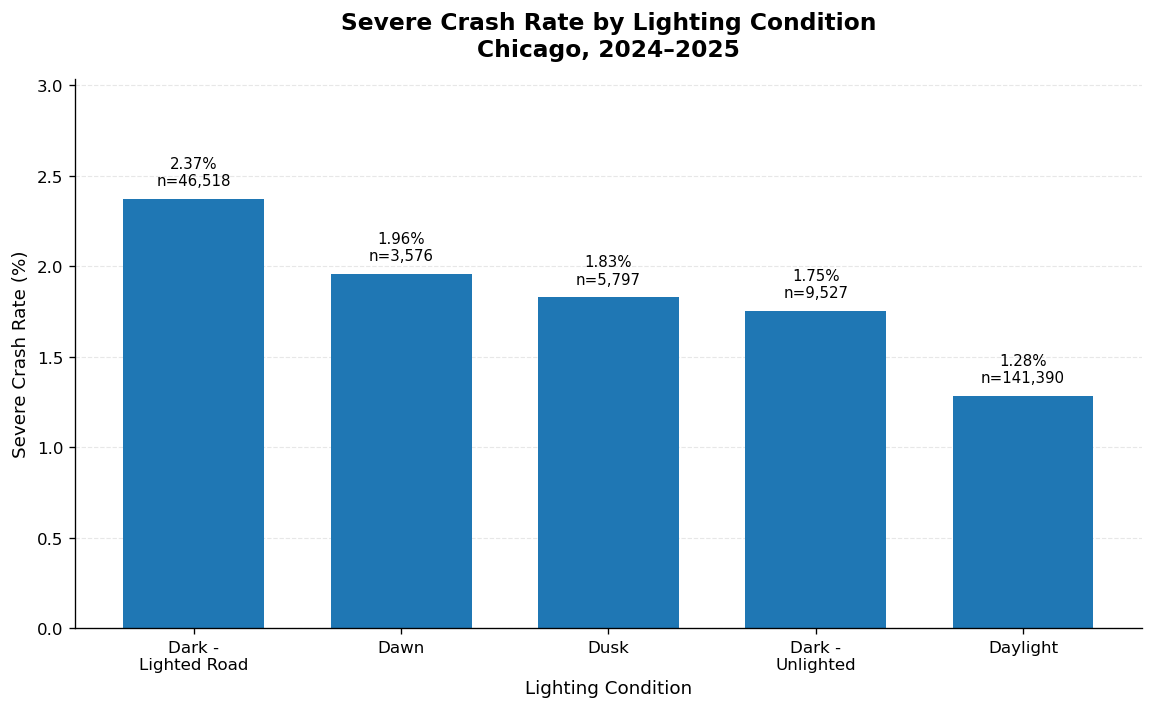

In [39]:
lighting_plot = (
    lighting_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
    .copy()
)

label_map = {
    "Dark - Lighted Road": "Dark -\nLighted Road",
    "Dark - Unlighted": "Dark -\nUnlighted",
    "Daylight": "Daylight",
    "Dawn": "Dawn",
    "Dusk": "Dusk"
}

lighting_plot["plot_label"] = (
    lighting_plot["lighting_group"]
    .map(label_map)
)

fig, ax = plt.subplots(
    figsize=(9.5, 5.8),
    constrained_layout=True
)

bars = ax.bar(
    lighting_plot["plot_label"],
    lighting_plot["severe_crash_rate_pct"],
    width=0.68
)

style_axes(ax, grid_axis="y")

max_rate = lighting_plot[
    "severe_crash_rate_pct"
].max()

ax.set_ylim(
    0,
    max_rate * 1.28
)

for bar, (_, row) in zip(
    bars,
    lighting_plot.iterrows()
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max_rate * 0.025,
        f'{row["severe_crash_rate_pct"]:.2f}%\n'
        f'n={int(row["total_crashes"]):,}',
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylabel("Severe Crash Rate (%)")
ax.set_xlabel("Lighting Condition")

ax.set_title(
    "Severe Crash Rate by Lighting Condition\n"
    "Chicago, 2024–2025",
    pad=14
)

plt.savefig(
    "lighting_severe_crash_rate_with_n.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [40]:
year_summary = (
    crashes
    .groupby("year")
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

year_summary["severe_crash_rate_pct"] = (
    year_summary["severe_crash_rate"] * 100
)

print(year_summary)

   year  total_crashes  severe_crashes  severe_crash_rate  \
0  2024         112057          1739.0           0.015554   
1  2025         109118          1573.0           0.014444   

   severe_crash_rate_pct  
0               1.555373  
1               1.444405  


In [41]:
month_summary = (
    crashes
    .groupby("month")
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

month_summary["severe_crash_rate_pct"] = (
    month_summary["severe_crash_rate"] * 100
)

print(month_summary)

    month  total_crashes  severe_crashes  severe_crash_rate  \
0       1          16456           214.0           0.013024   
1       2          15564           199.0           0.012806   
2       3          17666           246.0           0.013955   
3       4          18173           244.0           0.013464   
4       5          20846           308.0           0.014808   
5       6          20238           340.0           0.016827   
6       7          19434           315.0           0.016254   
7       8          20116           366.0           0.018233   
8       9          18859           327.0           0.017375   
9      10          18945           273.0           0.014447   
10     11          17462           273.0           0.015657   
11     12          17416           207.0           0.011912   

    severe_crash_rate_pct  
0                1.302416  
1                1.280649  
2                1.395507  
3                1.346430  
4                1.480840  
5           

In [42]:
month_names = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec"
}

month_summary["month_name"] = (
    month_summary["month"]
    .map(month_names)
)

print(month_summary)

    month  total_crashes  severe_crashes  severe_crash_rate  \
0       1          16456           214.0           0.013024   
1       2          15564           199.0           0.012806   
2       3          17666           246.0           0.013955   
3       4          18173           244.0           0.013464   
4       5          20846           308.0           0.014808   
5       6          20238           340.0           0.016827   
6       7          19434           315.0           0.016254   
7       8          20116           366.0           0.018233   
8       9          18859           327.0           0.017375   
9      10          18945           273.0           0.014447   
10     11          17462           273.0           0.015657   
11     12          17416           207.0           0.011912   

    severe_crash_rate_pct month_name  
0                1.302416        Jan  
1                1.280649        Feb  
2                1.395507        Mar  
3                1.34643

In [43]:
weekday_summary = (
    crashes
    .groupby(
        "day_of_week",
        observed=True
    )
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

weekday_summary["severe_crash_rate_pct"] = (
    weekday_summary["severe_crash_rate"] * 100
)

print(weekday_summary)

  day_of_week  total_crashes  severe_crashes  severe_crash_rate  \
0      Monday          30098           440.0           0.014651   
1     Tuesday          31680           424.0           0.013408   
2   Wednesday          31805           425.0           0.013383   
3    Thursday          32498           422.0           0.013012   
4      Friday          35256           487.0           0.013839   
5    Saturday          31814           553.0           0.017428   
6      Sunday          28024           561.0           0.020075   

   severe_crash_rate_pct  
0               1.465104  
1               1.340839  
2               1.338288  
3               1.301184  
4               1.383877  
5               1.742830  
6               2.007515  


In [44]:
hour_summary = (
    crashes
    .groupby("hour")
    .agg(
        total_crashes=("crash_record_id", "count"),
        severe_crashes=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

hour_summary["severe_crash_rate_pct"] = (
    hour_summary["severe_crash_rate"] * 100
)

print(hour_summary)

    hour  total_crashes  severe_crashes  severe_crash_rate  \
0      0           4852           116.0           0.024046   
1      1           4172           118.0           0.028447   
2      2           3528           106.0           0.030329   
3      3           3057            95.0           0.031332   
4      4           2566            69.0           0.027165   
5      5           3074            65.0           0.021263   
6      6           4685            80.0           0.017112   
7      7           9901           111.0           0.011230   
8      8          12406           125.0           0.010092   
9      9          10062           108.0           0.010745   
10    10          10051           108.0           0.010761   
11    11          11152           144.0           0.012935   
12    12          12598           145.0           0.011527   
13    13          12985           162.0           0.012493   
14    14          14549           188.0           0.012941   
15    15

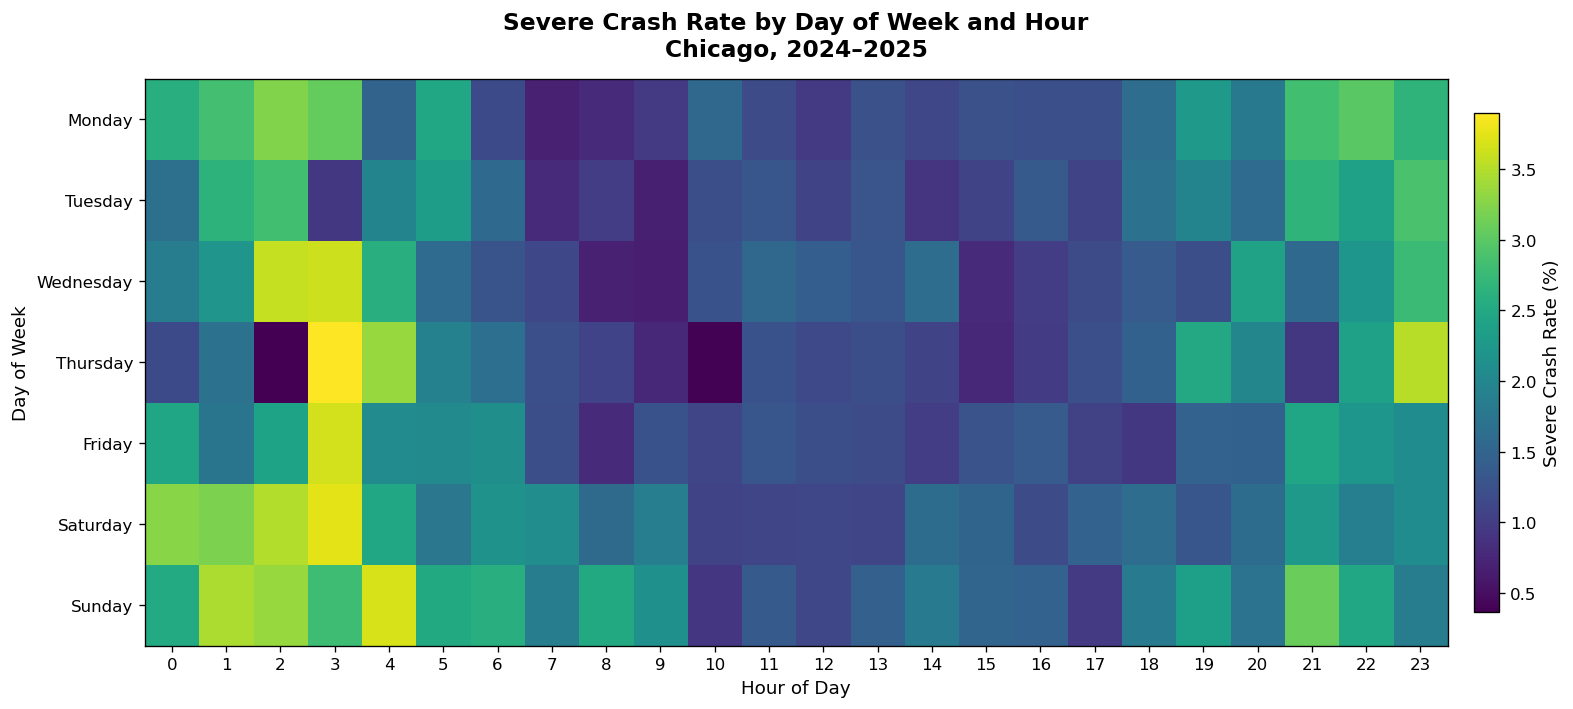

In [45]:
severe_heatmap_table = (
    crashes
    .groupby(
        ["day_of_week", "hour"],
        observed=True
    )["severe_crash"]
    .mean()
    .unstack()
    * 100
)

fig, ax = plt.subplots(
    figsize=(13, 5.8),
    constrained_layout=True
)

im = ax.imshow(
    severe_heatmap_table,
    aspect="auto",
    interpolation="nearest"
)

cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.88,
    pad=0.02
)

cbar.set_label("Severe Crash Rate (%)")

ax.set_xticks(np.arange(24))
ax.set_xticklabels(np.arange(24))

ax.set_yticks(
    np.arange(len(severe_heatmap_table.index))
)
ax.set_yticklabels(
    severe_heatmap_table.index
)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Day of Week")

ax.set_title(
    "Severe Crash Rate by Day of Week and Hour\n"
    "Chicago, 2024–2025",
    pad=14
)

plt.savefig(
    "severe_crash_rate_weekday_hour.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [46]:
vehicles = vehicles_clean.copy()

print(vehicles.shape)
print(vehicles["crash_record_id"].nunique())

(450185, 16)
221175


In [47]:
crash_severity_info = crashes[
    ["crash_record_id", "severity_group", "severe_crash"]
].copy()

In [48]:
vehicles_analysis = vehicles.merge(
    crash_severity_info,
    on="crash_record_id",
    how="left",
    validate="many_to_one"
)

print(vehicles_analysis.shape)

(450185, 18)


In [49]:
print(
    vehicles_analysis["severe_crash"]
    .value_counts(dropna=False)
)

print(
    vehicles_analysis["severity_group"]
    .value_counts(dropna=False)
)

severe_crash
0.0    442387
1.0      7063
NaN       735
Name: count, dtype: int64
severity_group
No Injury         372525
Minor Injury       69862
Serious Injury      6655
NaN                  735
Fatal                408
Name: count, dtype: int64


In [50]:
vehicles_analysis = vehicles_analysis[
    vehicles_analysis["severe_crash"].notna()
].copy()

In [51]:
vehicle_type_map = {
    "PASSENGER": "Passenger Car",
    "SPORT UTILITY VEHICLE (SUV)": "SUV",
    "VAN/MINI-VAN": "Van / Minivan",
    "PICKUP": "Pickup",

    "TRUCK - SINGLE UNIT": "Truck",
    "SINGLE UNIT TRUCK WITH TRAILER": "Truck",
    "TRACTOR W/ SEMI-TRAILER": "Truck",
    "TRACTOR W/O SEMI-TRAILER": "Truck",
    "OTHER VEHICLE WITH TRAILER": "Truck",

    "BUS OVER 15 PASS.": "Bus",
    "BUS UP TO 15 PASS.": "Bus",

    "MOTORCYCLE (OVER 150CC)": "Motorcycle",
    "3-WHEELED MOTORCYCLE (2 REAR WHEELS)": "Motorcycle",
    "MOPED OR MOTORIZED BICYCLE": "Motorcycle",
    "MOTOR DRIVEN CYCLE": "Motorcycle",
    "AUTOCYCLE": "Motorcycle",

    "ALL-TERRAIN VEHICLE (ATV)": "Other",
    "RECREATIONAL OFF-HIGHWAY VEHICLE (ROV)": "Other",
    "FARM EQUIPMENT": "Other",

    "OTHER": "Other",

    "UNKNOWN/NA": "Unknown"
}

vehicles_analysis["vehicle_type_group"] = (
    vehicles_analysis["vehicle_type"]
    .map(vehicle_type_map)
)

In [52]:
vehicle_type_analysis = vehicles_analysis[
    (vehicles_analysis["vehicle_type_group"].notna())
    & (vehicles_analysis["vehicle_type_group"] != "Unknown")
].copy()

In [53]:
vehicle_severity = (
    vehicle_type_analysis
    .groupby(
        "vehicle_type_group",
        observed=True
    )
    .agg(
        total_vehicle_records=("crash_unit_id", "count"),
        severe_involvements=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

In [54]:
vehicle_severity["severe_crash_rate_pct"] = (
    vehicle_severity["severe_crash_rate"] * 100
)

In [55]:
vehicle_severity = (
    vehicle_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
)

print(vehicle_severity)

  vehicle_type_group  total_vehicle_records  severe_involvements  \
1         Motorcycle                   1546                207.0   
2              Other                   6440                108.0   
3      Passenger Car                 265007               3672.0   
5                SUV                  73132                871.0   
7      Van / Minivan                  17239                193.0   
4             Pickup                  16992                186.0   
6              Truck                  13611                126.0   
0                Bus                   8575                 52.0   

   severe_crash_rate  severe_crash_rate_pct  
1           0.133894              13.389392  
2           0.016770               1.677019  
3           0.013856               1.385624  
5           0.011910               1.190997  
7           0.011196               1.119554  
4           0.010946               1.094633  
6           0.009257               0.925722  
0           0.00606

In [56]:
vehicle_severity_filtered = (
    vehicle_severity[
        vehicle_severity["total_vehicle_records"] >= 500
    ]
    .copy()
)

print(vehicle_severity_filtered)

  vehicle_type_group  total_vehicle_records  severe_involvements  \
1         Motorcycle                   1546                207.0   
2              Other                   6440                108.0   
3      Passenger Car                 265007               3672.0   
5                SUV                  73132                871.0   
7      Van / Minivan                  17239                193.0   
4             Pickup                  16992                186.0   
6              Truck                  13611                126.0   
0                Bus                   8575                 52.0   

   severe_crash_rate  severe_crash_rate_pct  
1           0.133894              13.389392  
2           0.016770               1.677019  
3           0.013856               1.385624  
5           0.011910               1.190997  
7           0.011196               1.119554  
4           0.010946               1.094633  
6           0.009257               0.925722  
0           0.00606

In [57]:
unit_type_analysis = vehicles_analysis[
    vehicles_analysis["unit_type"].notna()
].copy()

In [58]:
unit_type_severity = (
    unit_type_analysis
    .groupby("unit_type")
    .agg(
        total_records=("crash_unit_id", "count"),
        severe_involvements=("severe_crash", "sum"),
        severe_crash_rate=("severe_crash", "mean")
    )
    .reset_index()
)

In [59]:
unit_type_severity["severe_crash_rate_pct"] = (
    unit_type_severity["severe_crash_rate"] * 100
)

In [60]:
unit_type_severity = (
    unit_type_severity[
        unit_type_severity["total_records"] >= 500
    ]
    .sort_values(
        "severe_crash_rate_pct",
        ascending=False
    )
)

print(unit_type_severity)

           unit_type  total_records  severe_involvements  severe_crash_rate  \
8         PEDESTRIAN           6532                937.0           0.143448   
0            BICYCLE           4888                368.0           0.075286   
6  NON-MOTOR VEHICLE            530                 30.0           0.056604   
3         DRIVERLESS           1854                 31.0           0.016721   
2             DRIVER         376612               5139.0           0.013645   
7             PARKED          58601                547.0           0.009334   

   severe_crash_rate_pct  
8              14.344764  
0               7.528642  
6               5.660377  
3               1.672060  
2               1.364534  
7               0.933431  


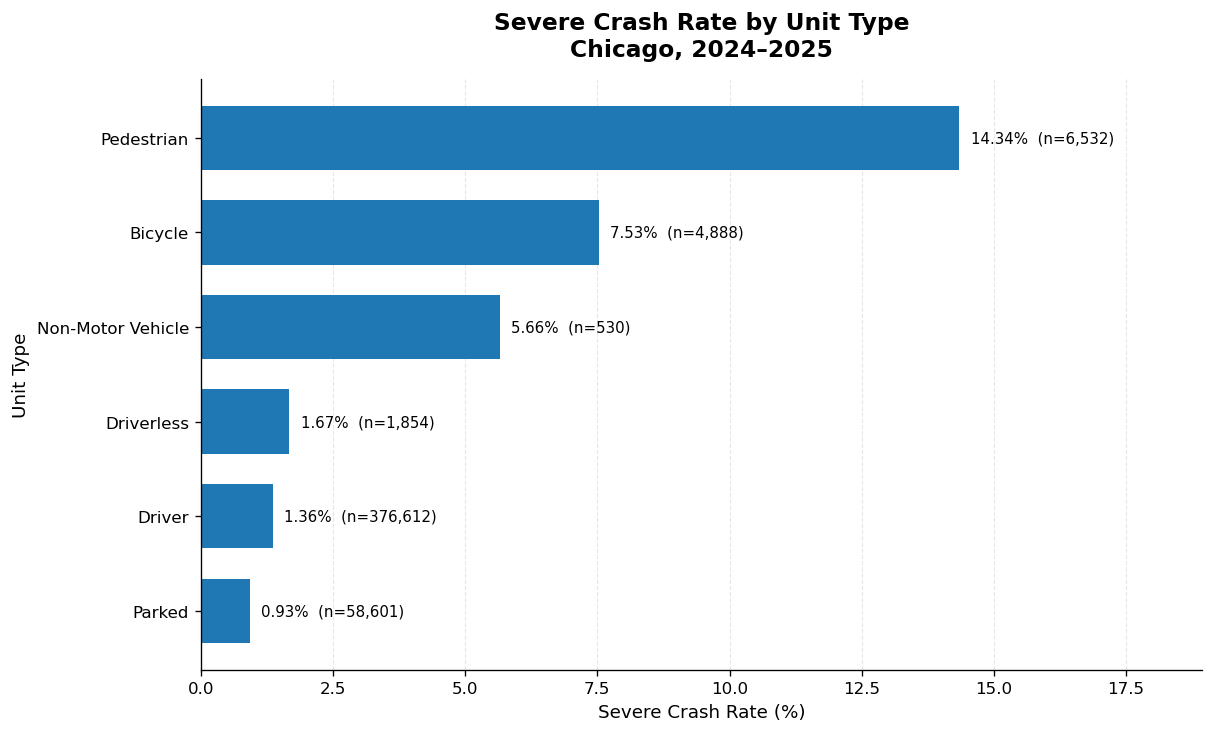

In [61]:
unit_plot = (
    unit_type_severity
    .sort_values(
        "severe_crash_rate_pct",
        ascending=True
    )
    .copy()
)

unit_label_map = {
    "PEDESTRIAN": "Pedestrian",
    "BICYCLE": "Bicycle",
    "NON-MOTOR VEHICLE": "Non-Motor Vehicle",
    "DRIVERLESS": "Driverless",
    "DRIVER": "Driver",
    "PARKED": "Parked"
}

unit_plot["plot_label"] = (
    unit_plot["unit_type"]
    .map(unit_label_map)
    .fillna(unit_plot["unit_type"])
)

fig, ax = plt.subplots(
    figsize=(10, 6),
    constrained_layout=True
)

bars = ax.barh(
    unit_plot["plot_label"],
    unit_plot["severe_crash_rate_pct"],
    height=0.68
)

style_axes(ax, grid_axis="x")

max_rate = unit_plot[
    "severe_crash_rate_pct"
].max()

ax.set_xlim(
    0,
    max_rate * 1.32
)

for bar, (_, row) in zip(
    bars,
    unit_plot.iterrows()
):
    ax.text(
        bar.get_width() + max_rate * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{row["severe_crash_rate_pct"]:.2f}%  '
        f'(n={int(row["total_records"]):,})',
        va="center",
        ha="left",
        fontsize=9
    )

ax.set_xlabel("Severe Crash Rate (%)")
ax.set_ylabel("Unit Type")

ax.set_title(
    "Severe Crash Rate by Unit Type\n"
    "Chicago, 2024–2025",
    pad=14
)

plt.savefig(
    "unit_type_severe_crash_rate.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

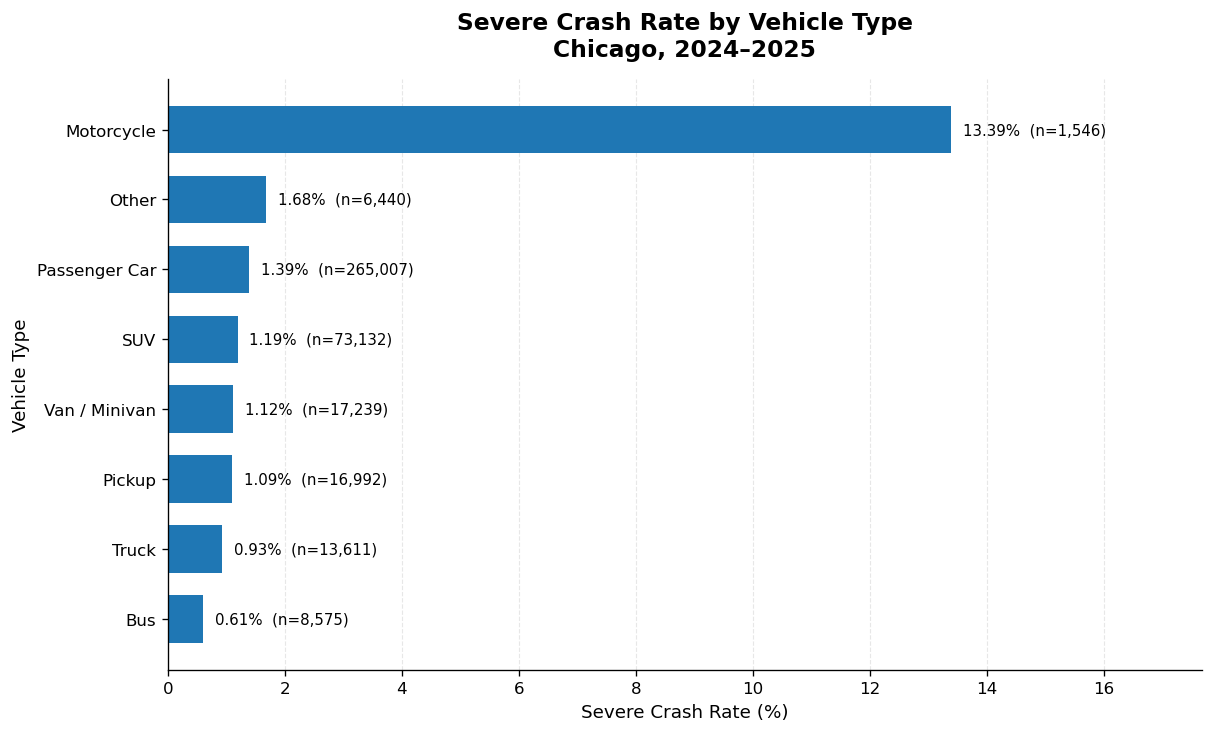

In [62]:
vehicle_plot = (
    vehicle_severity_filtered
    .sort_values(
        "severe_crash_rate_pct",
        ascending=True
    )
    .copy()
)

vehicle_label_map = {
    "Bus": "Bus",
    "Truck": "Truck",
    "Pickup": "Pickup",
    "Van / Minivan": "Van / Minivan",
    "SUV": "SUV",
    "Passenger Car": "Passenger Car",
    "Other": "Other",
    "Motorcycle": "Motorcycle"
}

vehicle_plot["plot_label"] = (
    vehicle_plot["vehicle_type_group"]
    .map(vehicle_label_map)
    .fillna(vehicle_plot["vehicle_type_group"])
)

fig, ax = plt.subplots(
    figsize=(10, 6),
    constrained_layout=True
)

bars = ax.barh(
    vehicle_plot["plot_label"],
    vehicle_plot["severe_crash_rate_pct"],
    height=0.68
)

style_axes(ax, grid_axis="x")

max_rate = vehicle_plot["severe_crash_rate_pct"].max()

ax.set_xlim(
    0,
    max_rate * 1.32
)

for bar, (_, row) in zip(
    bars,
    vehicle_plot.iterrows()
):
    ax.text(
        bar.get_width() + max_rate * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{row["severe_crash_rate_pct"]:.2f}%  '
        f'(n={int(row["total_vehicle_records"]):,})',
        va="center",
        ha="left",
        fontsize=9
    )

ax.set_xlabel("Severe Crash Rate (%)")
ax.set_ylabel("Vehicle Type")

ax.set_title(
    "Severe Crash Rate by Vehicle Type\n"
    "Chicago, 2024–2025",
    pad=14
)

plt.savefig(
    "vehicle_type_severe_crash_rate.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [63]:
crash_severity_info = crashes[
    ["crash_record_id", "severity_group", "severe_crash"]
].copy()

people_analysis = people_clean.merge(
    crash_severity_info,
    on="crash_record_id",
    how="left",
    validate="many_to_one"
)

print(people_analysis.shape)

print(
    people_analysis["severe_crash"]
    .value_counts(dropna=False)
)

(485110, 19)
severe_crash
0.0    476175
1.0      8933
NaN         2
Name: count, dtype: int64


In [64]:
people_analysis = people_analysis[
    people_analysis["severe_crash"].notna()
].copy()

In [65]:
# import numpy as np
# import pandas as pd
age_bins = [
    0,
    17,
    24,
    34,
    44,
    54,
    64,
    74,
    np.inf
]

age_labels = [
    "0–17",
    "18–24",
    "25–34",
    "35–44",
    "45–54",
    "55–64",
    "65–74",
    "75+"
]

people_analysis["age_group"] = pd.cut(
    people_analysis["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

In [66]:
# import numpy as np

people_analysis["person_severe_injury"] = np.where(
    people_analysis["injury_classification"].isna(),
    np.nan,
    np.where(
        people_analysis["injury_classification"].isin(
            ["FATAL", "INCAPACITATING INJURY"]
        ),
        1,
        0
    )
)

In [67]:
print(
    people_analysis["person_severe_injury"]
    .value_counts(dropna=False)
)

print(
    people_analysis["person_severe_injury"]
    .value_counts(normalize=True, dropna=False)
)

person_severe_injury
0.0    481182
1.0      3857
NaN        69
Name: count, dtype: int64
person_severe_injury
0.0    0.991907
1.0    0.007951
NaN    0.000142
Name: proportion, dtype: float64


In [68]:
age_injury = (
    people_analysis
    .dropna(
        subset=[
            "age_group",
            "person_severe_injury"
        ]
    )
    .groupby(
        "age_group",
        observed=True
    )
    .agg(
        total_people=("person_id", "count"),
        severe_injuries=("person_severe_injury", "sum"),
        severe_injury_rate=("person_severe_injury", "mean")
    )
    .reset_index()
)

age_injury["severe_injury_rate_pct"] = (
    age_injury["severe_injury_rate"] * 100
)

print(age_injury)

  age_group  total_people  severe_injuries  severe_injury_rate  \
0      0–17         24956            300.0            0.012021   
1     18–24         48910            555.0            0.011347   
2     25–34         90880            878.0            0.009661   
3     35–44         67398            633.0            0.009392   
4     45–54         49321            438.0            0.008881   
5     55–64         37456            392.0            0.010466   
6     65–74         20223            230.0            0.011373   
7       75+          8285            130.0            0.015691   

   severe_injury_rate_pct  
0                1.202116  
1                1.134737  
2                0.966109  
3                0.939197  
4                0.888060  
5                1.046561  
6                1.137319  
7                1.569101  


In [69]:
person_injury = (
    people_analysis
    .dropna(
        subset=[
            "person_type",
            "person_severe_injury"
        ]
    )
    .groupby("person_type")
    .agg(
        total_people=("person_id", "count"),
        severe_injuries=("person_severe_injury", "sum"),
        severe_injury_rate=("person_severe_injury", "mean")
    )
    .reset_index()
)

In [70]:
person_injury["severe_injury_rate_pct"] = (
    person_injury["severe_injury_rate"] * 100
)
person_injury = (
    person_injury[
        person_injury["total_people"] >= 500
    ]
    .sort_values(
        "severe_injury_rate_pct",
        ascending=False
    )
)

print(person_injury)

         person_type  total_people  severe_injuries  severe_injury_rate  \
5         PEDESTRIAN          6532            889.0            0.136099   
0            BICYCLE          4888            360.0            0.073650   
3  NON-MOTOR VEHICLE           529             27.0            0.051040   
4          PASSENGER         96428            793.0            0.008224   
1             DRIVER        376612           1788.0            0.004748   

   severe_injury_rate_pct  
5               13.609920  
0                7.364975  
3                5.103970  
4                0.822375  
1                0.474759  


In [71]:
crashes_geo = crashes[
    crashes["latitude"].notna()
    & crashes["longitude"].notna()
    & (crashes["latitude"] != 0)
    & (crashes["longitude"] != 0)
].copy()

severe_geo = crashes_geo[
    crashes_geo["severe_crash"] == 1
].copy()

print("All geocoded crashes:", len(crashes_geo))
print("Severe geocoded crashes:", len(severe_geo))

All geocoded crashes: 218830
Severe geocoded crashes: 3287


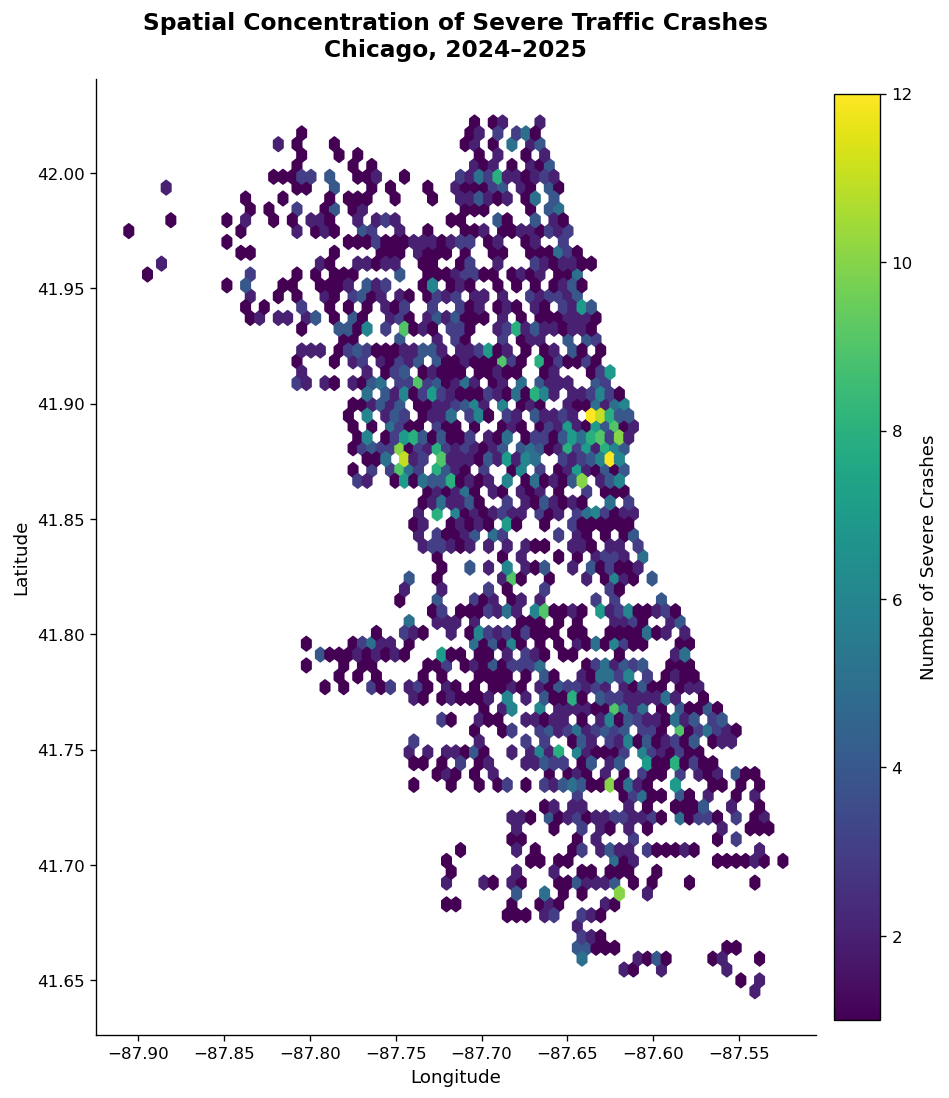

In [72]:
fig, ax = plt.subplots(
    figsize=(7.8, 9.5),
    constrained_layout=True
)

hb = ax.hexbin(
    severe_geo["longitude"],
    severe_geo["latitude"],
    gridsize=70,
    mincnt=1
)

cbar = fig.colorbar(
    hb,
    ax=ax,
    shrink=0.82,
    pad=0.025
)

cbar.set_label(
    "Number of Severe Crashes"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_title(
    "Spatial Concentration of Severe Traffic Crashes\n"
    "Chicago, 2024–2025",
    pad=14
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep a natural geographic aspect
ax.set_aspect(
    1 / np.cos(
        np.deg2rad(
            severe_geo["latitude"].mean()
        )
    )
)

plt.savefig(
    "chicago_severe_crashes_hexbin.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

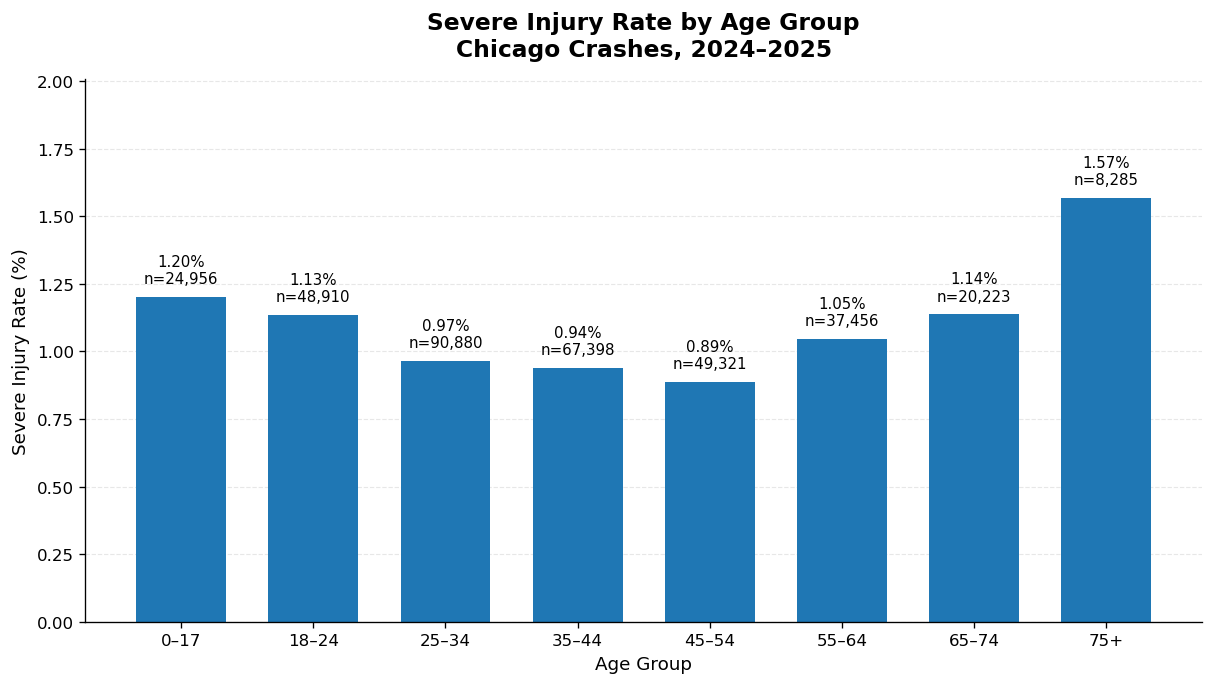

In [73]:
age_plot = age_injury.copy()

fig, ax = plt.subplots(
    figsize=(10, 5.6),
    constrained_layout=True
)

bars = ax.bar(
    age_plot["age_group"].astype(str),
    age_plot["severe_injury_rate_pct"],
    width=0.68
)

style_axes(ax, grid_axis="y")

max_rate = age_plot[
    "severe_injury_rate_pct"
].max()

ax.set_ylim(
    0,
    max_rate * 1.28
)

for bar, (_, row) in zip(
    bars,
    age_plot.iterrows()
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max_rate * 0.025,
        f'{row["severe_injury_rate_pct"]:.2f}%\n'
        f'n={int(row["total_people"]):,}',
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_xlabel("Age Group")
ax.set_ylabel("Severe Injury Rate (%)")

ax.set_title(
    "Severe Injury Rate by Age Group\n"
    "Chicago Crashes, 2024–2025",
    pad=14
)

plt.savefig(
    "age_group_severe_injury_rate.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [74]:
final_figures = {
    "Figure 1": "severe_crash_rate_weekday_hour.svg",
    "Figure 2": "lighting_severe_crash_rate_with_n.svg",
    "Figure 3": "unit_type_severe_crash_rate.svg",
    "Figure 4": "age_group_severe_injury_rate.svg",
    "Figure 5": "chicago_severe_crashes_hexbin.svg",
    "Supporting Figure": "vehicle_type_severe_crash_rate.svg"
}

for k, v in final_figures.items():
    print(f"{k}: {v}")

Figure 1: severe_crash_rate_weekday_hour.svg
Figure 2: lighting_severe_crash_rate_with_n.svg
Figure 3: unit_type_severe_crash_rate.svg
Figure 4: age_group_severe_injury_rate.svg
Figure 5: chicago_severe_crashes_hexbin.svg
Supporting Figure: vehicle_type_severe_crash_rate.svg
